In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import xgboost as xgb

In [2]:
df=pd.read_csv('Merge_data_v5_selected.csv')

In [3]:
df['move_type'] = df['total_count'].apply(lambda x: 0 if x == 0 else 1 if 1 <= x <= 4 else 2)

In [4]:
del df['Unnamed: 0']

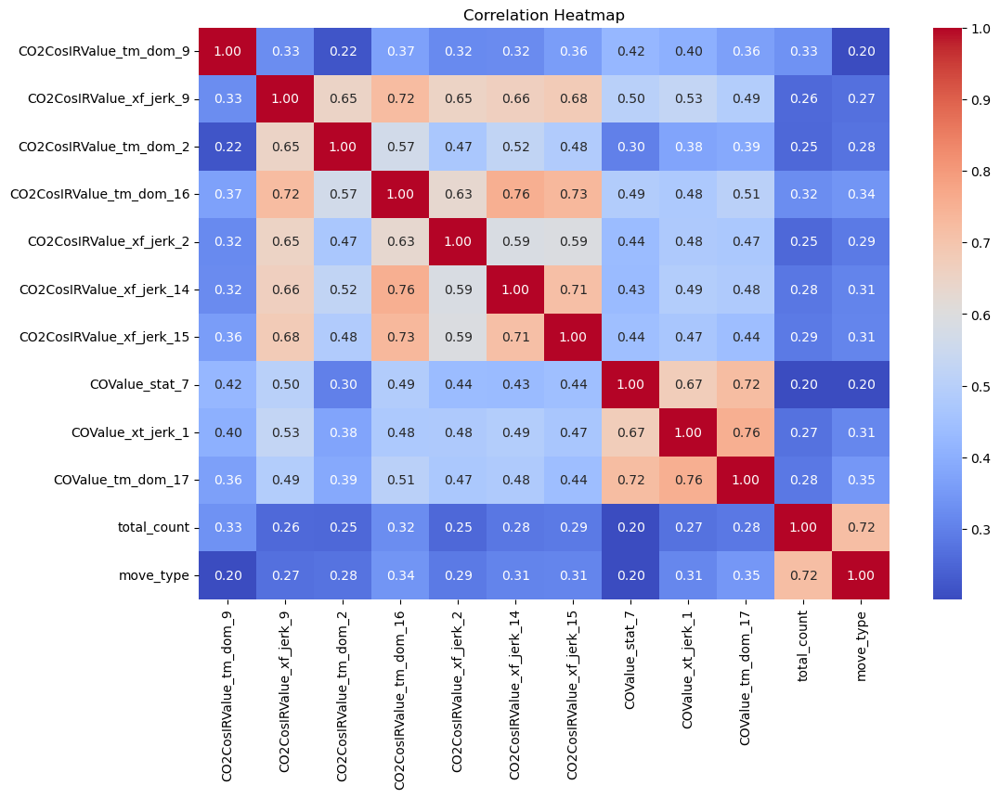

In [5]:
import seaborn as sns
correlation_matrix = df.corr()

# Create a heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap')
plt.show()

In [6]:
drop_features = ['total_count','move_type']
target_feature = 'move_type'

In [7]:
X = df.drop(drop_features, axis=1)
y = df[target_feature]

In [9]:
from catboost import CatBoostClassifier, Pool, cv
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
scores=[]
for i in range(1000):
    X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.25,random_state=i)
    model = CatBoostClassifier(iterations=100, depth=5, learning_rate=0.1, loss_function='MultiClass', random_seed=i)
    model.fit(X_train,y_train)
    y_pred=model.predict(X_test)
    scores.append(accuracy_score(y_test, y_pred))

0:	learn: 1.0382529	total: 59.1ms	remaining: 5.85s
1:	learn: 0.9861304	total: 60ms	remaining: 2.94s
2:	learn: 0.9458589	total: 61ms	remaining: 1.97s
3:	learn: 0.9105064	total: 61.8ms	remaining: 1.48s
4:	learn: 0.8865793	total: 62.8ms	remaining: 1.19s
5:	learn: 0.8602320	total: 63.6ms	remaining: 997ms
6:	learn: 0.8397271	total: 64.5ms	remaining: 858ms
7:	learn: 0.8190216	total: 66.3ms	remaining: 762ms
8:	learn: 0.8005402	total: 67.1ms	remaining: 679ms
9:	learn: 0.7830302	total: 68.1ms	remaining: 613ms
10:	learn: 0.7695960	total: 69ms	remaining: 558ms
11:	learn: 0.7574176	total: 69.9ms	remaining: 512ms
12:	learn: 0.7478497	total: 70.7ms	remaining: 473ms
13:	learn: 0.7394763	total: 71.6ms	remaining: 440ms
14:	learn: 0.7345419	total: 72.3ms	remaining: 410ms
15:	learn: 0.7253136	total: 73.3ms	remaining: 385ms
16:	learn: 0.7179753	total: 74.2ms	remaining: 362ms
17:	learn: 0.7098763	total: 75.1ms	remaining: 342ms
18:	learn: 0.7060734	total: 76ms	remaining: 324ms
19:	learn: 0.6999762	total: 77

94:	learn: 0.5679722	total: 95.9ms	remaining: 5.05ms
95:	learn: 0.5670573	total: 97.1ms	remaining: 4.05ms
96:	learn: 0.5660656	total: 98.1ms	remaining: 3.04ms
97:	learn: 0.5642703	total: 99.2ms	remaining: 2.02ms
98:	learn: 0.5619609	total: 100ms	remaining: 1.01ms
99:	learn: 0.5606012	total: 101ms	remaining: 0us
0:	learn: 1.0350344	total: 895us	remaining: 88.7ms
1:	learn: 0.9846490	total: 1.78ms	remaining: 87.1ms
2:	learn: 0.9449348	total: 2.73ms	remaining: 88.1ms
3:	learn: 0.9098757	total: 3.61ms	remaining: 86.7ms
4:	learn: 0.8777391	total: 4.57ms	remaining: 86.8ms
5:	learn: 0.8511592	total: 5.59ms	remaining: 87.6ms
6:	learn: 0.8308328	total: 6.9ms	remaining: 91.7ms
7:	learn: 0.8109952	total: 8.03ms	remaining: 92.3ms
8:	learn: 0.7919544	total: 9.14ms	remaining: 92.4ms
9:	learn: 0.7790696	total: 10.2ms	remaining: 92.1ms
10:	learn: 0.7659987	total: 11.4ms	remaining: 92.5ms
11:	learn: 0.7565833	total: 12.5ms	remaining: 91.5ms
12:	learn: 0.7468787	total: 13.6ms	remaining: 91.3ms
13:	learn:

82:	learn: 0.5814504	total: 81.9ms	remaining: 16.8ms
83:	learn: 0.5798283	total: 83.1ms	remaining: 15.8ms
84:	learn: 0.5782635	total: 84.1ms	remaining: 14.8ms
85:	learn: 0.5761708	total: 85.3ms	remaining: 13.9ms
86:	learn: 0.5749504	total: 86.2ms	remaining: 12.9ms
87:	learn: 0.5735646	total: 87.2ms	remaining: 11.9ms
88:	learn: 0.5722706	total: 88.2ms	remaining: 10.9ms
89:	learn: 0.5706032	total: 89.2ms	remaining: 9.91ms
90:	learn: 0.5694908	total: 90.1ms	remaining: 8.91ms
91:	learn: 0.5680812	total: 91.1ms	remaining: 7.92ms
92:	learn: 0.5663780	total: 92.1ms	remaining: 6.93ms
93:	learn: 0.5654806	total: 93.1ms	remaining: 5.94ms
94:	learn: 0.5643097	total: 94.1ms	remaining: 4.95ms
95:	learn: 0.5635426	total: 95.1ms	remaining: 3.96ms
96:	learn: 0.5618748	total: 96ms	remaining: 2.97ms
97:	learn: 0.5604610	total: 97ms	remaining: 1.98ms
98:	learn: 0.5594946	total: 98.1ms	remaining: 990us
99:	learn: 0.5578568	total: 99.2ms	remaining: 0us
0:	learn: 1.0357236	total: 853us	remaining: 84.5ms
1:	

76:	learn: 0.5865496	total: 75.1ms	remaining: 22.4ms
77:	learn: 0.5858155	total: 76.2ms	remaining: 21.5ms
78:	learn: 0.5848478	total: 77.2ms	remaining: 20.5ms
79:	learn: 0.5838730	total: 78.2ms	remaining: 19.5ms
80:	learn: 0.5816523	total: 79.3ms	remaining: 18.6ms
81:	learn: 0.5799167	total: 80.4ms	remaining: 17.6ms
82:	learn: 0.5784313	total: 81.4ms	remaining: 16.7ms
83:	learn: 0.5767955	total: 82.3ms	remaining: 15.7ms
84:	learn: 0.5752447	total: 83.5ms	remaining: 14.7ms
85:	learn: 0.5744302	total: 84.4ms	remaining: 13.7ms
86:	learn: 0.5732998	total: 85.6ms	remaining: 12.8ms
87:	learn: 0.5719346	total: 86.5ms	remaining: 11.8ms
88:	learn: 0.5709969	total: 87.6ms	remaining: 10.8ms
89:	learn: 0.5696546	total: 88.6ms	remaining: 9.85ms
90:	learn: 0.5683531	total: 89.7ms	remaining: 8.88ms
91:	learn: 0.5678183	total: 90.7ms	remaining: 7.89ms
92:	learn: 0.5668843	total: 92.2ms	remaining: 6.94ms
93:	learn: 0.5652850	total: 93.2ms	remaining: 5.95ms
94:	learn: 0.5638684	total: 94.2ms	remaining: 

66:	learn: 0.6079471	total: 66.1ms	remaining: 32.5ms
67:	learn: 0.6060566	total: 67.2ms	remaining: 31.6ms
68:	learn: 0.6038434	total: 68ms	remaining: 30.6ms
69:	learn: 0.6029419	total: 69ms	remaining: 29.6ms
70:	learn: 0.6013694	total: 70ms	remaining: 28.6ms
71:	learn: 0.5992910	total: 71ms	remaining: 27.6ms
72:	learn: 0.5979061	total: 72ms	remaining: 26.6ms
73:	learn: 0.5966904	total: 73ms	remaining: 25.7ms
74:	learn: 0.5955876	total: 74ms	remaining: 24.7ms
75:	learn: 0.5940625	total: 74.9ms	remaining: 23.7ms
76:	learn: 0.5925150	total: 76.1ms	remaining: 22.7ms
77:	learn: 0.5915895	total: 77ms	remaining: 21.7ms
78:	learn: 0.5901913	total: 78ms	remaining: 20.7ms
79:	learn: 0.5889871	total: 79ms	remaining: 19.8ms
80:	learn: 0.5873176	total: 79.9ms	remaining: 18.8ms
81:	learn: 0.5860579	total: 81ms	remaining: 17.8ms
82:	learn: 0.5840953	total: 82ms	remaining: 16.8ms
83:	learn: 0.5833404	total: 82.8ms	remaining: 15.8ms
84:	learn: 0.5816315	total: 83.8ms	remaining: 14.8ms
85:	learn: 0.5805

...

20:	learn: 0.6827082	total: 20.6ms	remaining: 77.3ms
21:	learn: 0.6786964	total: 21.7ms	remaining: 77ms
22:	learn: 0.6744003	total: 22.7ms	remaining: 75.9ms
23:	learn: 0.6702784	total: 23.7ms	remaining: 74.9ms
24:	learn: 0.6671670	total: 24.8ms	remaining: 74.3ms
25:	learn: 0.6639853	total: 26ms	remaining: 73.9ms
26:	learn: 0.6613280	total: 27ms	remaining: 73ms
27:	learn: 0.6588281	total: 28.1ms	remaining: 72.2ms
28:	learn: 0.6553125	total: 29ms	remaining: 71ms
29:	learn: 0.6525226	total: 29.9ms	remaining: 69.7ms
30:	learn: 0.6494767	total: 30.8ms	remaining: 68.6ms
31:	learn: 0.6477208	total: 31.7ms	remaining: 67.3ms
32:	learn: 0.6455365	total: 32.6ms	remaining: 66.1ms
33:	learn: 0.6437433	total: 33.4ms	remaining: 64.8ms
34:	learn: 0.6411769	total: 34.5ms	remaining: 64ms
35:	learn: 0.6398618	total: 35.4ms	remaining: 62.9ms
36:	learn: 0.6374351	total: 36.4ms	remaining: 62ms
37:	learn: 0.6356818	total: 37.3ms	remaining: 60.9ms
38:	learn: 0.6341936	total: 38.3ms	remaining: 59.9ms
39:	learn

13:	learn: 0.7576459	total: 14.2ms	remaining: 87.1ms
14:	learn: 0.7500253	total: 15.2ms	remaining: 86.4ms
15:	learn: 0.7435349	total: 16.3ms	remaining: 85.5ms
16:	learn: 0.7364749	total: 17.3ms	remaining: 84.3ms
17:	learn: 0.7296845	total: 18.3ms	remaining: 83.5ms
18:	learn: 0.7239894	total: 19.8ms	remaining: 84.5ms
19:	learn: 0.7170689	total: 20.8ms	remaining: 83ms
20:	learn: 0.7125735	total: 21.6ms	remaining: 81.4ms
21:	learn: 0.7074419	total: 22.6ms	remaining: 80.2ms
22:	learn: 0.7031641	total: 23.5ms	remaining: 78.7ms
23:	learn: 0.6972874	total: 24.5ms	remaining: 77.6ms
24:	learn: 0.6938769	total: 25.5ms	remaining: 76.6ms
25:	learn: 0.6892482	total: 26.7ms	remaining: 75.9ms
26:	learn: 0.6860199	total: 27.6ms	remaining: 74.5ms
27:	learn: 0.6817788	total: 28.6ms	remaining: 73.5ms
28:	learn: 0.6795916	total: 29.6ms	remaining: 72.6ms
29:	learn: 0.6765254	total: 30.5ms	remaining: 71.3ms
30:	learn: 0.6733419	total: 31.7ms	remaining: 70.5ms
31:	learn: 0.6715338	total: 32.8ms	remaining: 69

5:	learn: 0.8614055	total: 6.13ms	remaining: 96.1ms
6:	learn: 0.8401368	total: 7.33ms	remaining: 97.4ms
7:	learn: 0.8203240	total: 8.27ms	remaining: 95.1ms
8:	learn: 0.8021504	total: 9.24ms	remaining: 93.5ms
9:	learn: 0.7861113	total: 10.3ms	remaining: 92.3ms
10:	learn: 0.7714127	total: 11.3ms	remaining: 91.3ms
11:	learn: 0.7568438	total: 12.4ms	remaining: 91.2ms
12:	learn: 0.7454978	total: 13.3ms	remaining: 88.7ms
13:	learn: 0.7372721	total: 14.1ms	remaining: 86.5ms
14:	learn: 0.7279420	total: 15ms	remaining: 84.8ms
15:	learn: 0.7198811	total: 15.9ms	remaining: 83.2ms
16:	learn: 0.7125359	total: 16.7ms	remaining: 81.7ms
17:	learn: 0.7069484	total: 17.6ms	remaining: 80ms
18:	learn: 0.7016178	total: 18.5ms	remaining: 78.8ms
19:	learn: 0.6970589	total: 19.5ms	remaining: 77.9ms
20:	learn: 0.6927120	total: 20.5ms	remaining: 77ms
21:	learn: 0.6876366	total: 21.4ms	remaining: 75.7ms
22:	learn: 0.6834271	total: 22.3ms	remaining: 74.6ms
23:	learn: 0.6803692	total: 23.2ms	remaining: 73.5ms
24:	

95:	learn: 0.5588150	total: 101ms	remaining: 4.19ms
96:	learn: 0.5571724	total: 102ms	remaining: 3.15ms
97:	learn: 0.5563067	total: 103ms	remaining: 2.1ms
98:	learn: 0.5545719	total: 104ms	remaining: 1.05ms
99:	learn: 0.5533004	total: 105ms	remaining: 0us
0:	learn: 1.0383704	total: 993us	remaining: 98.4ms
1:	learn: 0.9912255	total: 2ms	remaining: 98ms
2:	learn: 0.9488652	total: 3ms	remaining: 97ms
3:	learn: 0.9166004	total: 4.09ms	remaining: 98.2ms
4:	learn: 0.8871133	total: 5.08ms	remaining: 96.5ms
5:	learn: 0.8642904	total: 6.08ms	remaining: 95.2ms
6:	learn: 0.8454081	total: 7.75ms	remaining: 103ms
7:	learn: 0.8259853	total: 8.77ms	remaining: 101ms
8:	learn: 0.8126385	total: 9.84ms	remaining: 99.5ms
9:	learn: 0.7970655	total: 10.9ms	remaining: 98.4ms
10:	learn: 0.7841720	total: 11.9ms	remaining: 96.2ms
11:	learn: 0.7716159	total: 13ms	remaining: 95.2ms
12:	learn: 0.7598922	total: 14ms	remaining: 93.7ms
13:	learn: 0.7495900	total: 15ms	remaining: 92.1ms
14:	learn: 0.7395561	total: 16m

67:	learn: 0.6110598	total: 76.3ms	remaining: 35.9ms
68:	learn: 0.6101764	total: 77.5ms	remaining: 34.8ms
69:	learn: 0.6067766	total: 78.4ms	remaining: 33.6ms
70:	learn: 0.6053484	total: 79.4ms	remaining: 32.4ms
71:	learn: 0.6030819	total: 80.4ms	remaining: 31.3ms
72:	learn: 0.6016076	total: 81.4ms	remaining: 30.1ms
73:	learn: 0.6000069	total: 82.4ms	remaining: 29ms
74:	learn: 0.5981266	total: 84ms	remaining: 28ms
75:	learn: 0.5974628	total: 85.1ms	remaining: 26.9ms
76:	learn: 0.5957204	total: 86.2ms	remaining: 25.8ms
77:	learn: 0.5943671	total: 87.3ms	remaining: 24.6ms
78:	learn: 0.5930863	total: 88.8ms	remaining: 23.6ms
79:	learn: 0.5916385	total: 90.1ms	remaining: 22.5ms
80:	learn: 0.5907198	total: 91.4ms	remaining: 21.4ms
81:	learn: 0.5890265	total: 92.7ms	remaining: 20.3ms
82:	learn: 0.5872206	total: 93.6ms	remaining: 19.2ms
83:	learn: 0.5858154	total: 94.7ms	remaining: 18ms
84:	learn: 0.5843430	total: 95.8ms	remaining: 16.9ms
85:	learn: 0.5832833	total: 96.8ms	remaining: 15.8ms
8

In [10]:
np.argmax(scores)

903

In [11]:
scores[np.argmax(scores)]

0.7402061855670103

In [17]:
from sklearn.metrics import classification_report

In [23]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.25,random_state=903)

In [24]:
from sklearn.model_selection import GridSearchCV

In [33]:
model = CatBoostClassifier(iterations=300, depth=6, learning_rate=0.05, l2_leaf_reg=5,loss_function='MultiClass')
model.fit(X_train,y_train)
y_pred=model.predict(X_test)

0:	learn: 1.0718161	total: 3.03ms	remaining: 906ms
1:	learn: 1.0472821	total: 5.86ms	remaining: 873ms
2:	learn: 1.0254908	total: 7.71ms	remaining: 763ms
3:	learn: 1.0059722	total: 9.74ms	remaining: 721ms
4:	learn: 0.9863420	total: 11.5ms	remaining: 679ms
5:	learn: 0.9683838	total: 13.2ms	remaining: 645ms
6:	learn: 0.9518259	total: 14.8ms	remaining: 619ms
7:	learn: 0.9367478	total: 16.6ms	remaining: 606ms
8:	learn: 0.9230368	total: 18.7ms	remaining: 606ms
9:	learn: 0.9097617	total: 20.4ms	remaining: 593ms
10:	learn: 0.8972283	total: 22.3ms	remaining: 586ms
11:	learn: 0.8869861	total: 24.1ms	remaining: 579ms
12:	learn: 0.8761773	total: 25.8ms	remaining: 569ms
13:	learn: 0.8657120	total: 27.6ms	remaining: 564ms
14:	learn: 0.8558928	total: 30.1ms	remaining: 572ms
15:	learn: 0.8477451	total: 32.2ms	remaining: 572ms
16:	learn: 0.8391981	total: 35.4ms	remaining: 589ms
17:	learn: 0.8307896	total: 37.2ms	remaining: 583ms
18:	learn: 0.8225076	total: 39ms	remaining: 577ms
19:	learn: 0.8150131	tot

258:	learn: 0.5215831	total: 399ms	remaining: 63.2ms
259:	learn: 0.5209407	total: 401ms	remaining: 61.7ms
260:	learn: 0.5200640	total: 403ms	remaining: 60.2ms
261:	learn: 0.5190620	total: 404ms	remaining: 58.6ms
262:	learn: 0.5183307	total: 406ms	remaining: 57.1ms
263:	learn: 0.5177955	total: 408ms	remaining: 55.6ms
264:	learn: 0.5169132	total: 409ms	remaining: 54.1ms
265:	learn: 0.5164431	total: 411ms	remaining: 52.6ms
266:	learn: 0.5154936	total: 413ms	remaining: 51ms
267:	learn: 0.5149925	total: 415ms	remaining: 49.5ms
268:	learn: 0.5146916	total: 416ms	remaining: 48ms
269:	learn: 0.5139089	total: 418ms	remaining: 46.4ms
270:	learn: 0.5135976	total: 419ms	remaining: 44.9ms
271:	learn: 0.5130596	total: 421ms	remaining: 43.3ms
272:	learn: 0.5123945	total: 422ms	remaining: 41.8ms
273:	learn: 0.5121741	total: 424ms	remaining: 40.2ms
274:	learn: 0.5115302	total: 425ms	remaining: 38.7ms
275:	learn: 0.5107750	total: 427ms	remaining: 37.1ms
276:	learn: 0.5099110	total: 429ms	remaining: 35.6

In [34]:
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)

print(f"Accuracy: {accuracy:.2f}")
print("Classification Report:\n", report)

Accuracy: 0.72
Classification Report:
               precision    recall  f1-score   support

           0       0.90      0.88      0.89       117
           1       0.49      0.29      0.37       119
           2       0.70      0.85      0.77       249

    accuracy                           0.72       485
   macro avg       0.70      0.67      0.68       485
weighted avg       0.70      0.72      0.70       485



In [35]:
y_pred_train = model.predict(X_train)
accuracy = accuracy_score(y_train, y_pred_train)
print(f'Accuracy: {accuracy}')

Accuracy: 0.811424638678596


In [18]:
catboost_classifier = CatBoostClassifier(
    iterations=100,
    depth=5,
    learning_rate=0.1,
    loss_function='MultiClass',
    bootstrap_type='Bayesian',  # Bayesian bootstrap
    random_seed=42
)

# Define a grid of hyperparameters to search
param_grid = {
    'iterations': [100, 200, 300],
    'depth': [4, 6, 8],
    'learning_rate': [0.01, 0.05, 0.1],
    'l2_leaf_reg': [1, 3, 5, 7, 9],
}

# Create the GridSearchCV object
grid_search = GridSearchCV(estimator=catboost_classifier, param_grid=param_grid, scoring='accuracy', cv=5)

# Perform the grid search on the training data
grid_search.fit(X_train, y_train)

# Get the best parameters and the best model
best_params = grid_search.best_params_
best_model = grid_search.best_estimator_

# Make predictions on the test set using the best model
y_pred = best_model.predict(X_test)

# Evaluate the performance of the best model
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)

print("Best Parameters:", best_params)
print(f"Accuracy with Best Model: {accuracy:.2f}")
print("Classification Report:\n", report)

0:	learn: 1.0924700	total: 988us	remaining: 97.8ms
1:	learn: 1.0863888	total: 1.79ms	remaining: 87.9ms
2:	learn: 1.0805782	total: 2.41ms	remaining: 78ms
3:	learn: 1.0753410	total: 3.06ms	remaining: 73.5ms
4:	learn: 1.0697432	total: 3.71ms	remaining: 70.4ms
5:	learn: 1.0641412	total: 4.42ms	remaining: 69.2ms
6:	learn: 1.0589936	total: 5.08ms	remaining: 67.5ms
7:	learn: 1.0536147	total: 5.68ms	remaining: 65.3ms
8:	learn: 1.0484615	total: 6.27ms	remaining: 63.4ms
9:	learn: 1.0441415	total: 6.89ms	remaining: 62ms
10:	learn: 1.0396924	total: 7.56ms	remaining: 61.2ms
11:	learn: 1.0350593	total: 8.17ms	remaining: 59.9ms
12:	learn: 1.0307980	total: 8.76ms	remaining: 58.6ms
13:	learn: 1.0261239	total: 9.32ms	remaining: 57.3ms
14:	learn: 1.0213210	total: 9.87ms	remaining: 56ms
15:	learn: 1.0171197	total: 10.4ms	remaining: 54.8ms
16:	learn: 1.0129593	total: 11ms	remaining: 53.6ms
17:	learn: 1.0093418	total: 11.5ms	remaining: 52.4ms
18:	learn: 1.0054669	total: 12.1ms	remaining: 51.5ms
19:	learn: 1

0:	learn: 1.0923966	total: 617us	remaining: 61.2ms
1:	learn: 1.0866224	total: 1.31ms	remaining: 64.2ms
2:	learn: 1.0810215	total: 2.09ms	remaining: 67.6ms
3:	learn: 1.0757308	total: 2.69ms	remaining: 64.6ms
4:	learn: 1.0701502	total: 3.57ms	remaining: 67.8ms
5:	learn: 1.0644398	total: 4.18ms	remaining: 65.6ms
6:	learn: 1.0589363	total: 4.81ms	remaining: 64ms
7:	learn: 1.0537997	total: 5.33ms	remaining: 61.3ms
8:	learn: 1.0486197	total: 5.91ms	remaining: 59.8ms
9:	learn: 1.0433783	total: 6.49ms	remaining: 58.4ms
10:	learn: 1.0381722	total: 7.1ms	remaining: 57.5ms
11:	learn: 1.0334331	total: 7.68ms	remaining: 56.3ms
12:	learn: 1.0290368	total: 8.35ms	remaining: 55.9ms
13:	learn: 1.0249883	total: 8.99ms	remaining: 55.2ms
14:	learn: 1.0202296	total: 9.72ms	remaining: 55.1ms
15:	learn: 1.0159643	total: 10.4ms	remaining: 54.7ms
16:	learn: 1.0117387	total: 11ms	remaining: 53.7ms
17:	learn: 1.0077803	total: 11.6ms	remaining: 53ms
18:	learn: 1.0034909	total: 12.8ms	remaining: 54.7ms
19:	learn: 

97:	learn: 0.6608326	total: 63.3ms	remaining: 1.29ms
98:	learn: 0.6602810	total: 64.1ms	remaining: 647us
99:	learn: 0.6593945	total: 64.7ms	remaining: 0us
0:	learn: 1.0685298	total: 720us	remaining: 71.3ms
1:	learn: 1.0415198	total: 1.46ms	remaining: 71.5ms
2:	learn: 1.0169473	total: 2ms	remaining: 64.6ms
3:	learn: 0.9962770	total: 2.6ms	remaining: 62.4ms
4:	learn: 0.9782115	total: 3.21ms	remaining: 61.1ms
5:	learn: 0.9596057	total: 3.77ms	remaining: 59.1ms
6:	learn: 0.9422336	total: 4.35ms	remaining: 57.8ms
7:	learn: 0.9287165	total: 4.92ms	remaining: 56.6ms
8:	learn: 0.9140379	total: 5.51ms	remaining: 55.8ms
9:	learn: 0.9023021	total: 6.24ms	remaining: 56.2ms
10:	learn: 0.8895579	total: 6.85ms	remaining: 55.4ms
11:	learn: 0.8776934	total: 7.41ms	remaining: 54.4ms
12:	learn: 0.8675603	total: 8.04ms	remaining: 53.8ms
13:	learn: 0.8569730	total: 8.76ms	remaining: 53.8ms
14:	learn: 0.8466918	total: 9.4ms	remaining: 53.3ms
15:	learn: 0.8396614	total: 10ms	remaining: 52.5ms
16:	learn: 0.83

92:	learn: 0.6582605	total: 60.1ms	remaining: 4.52ms
93:	learn: 0.6570672	total: 60.9ms	remaining: 3.89ms
94:	learn: 0.6562900	total: 61.5ms	remaining: 3.23ms
95:	learn: 0.6545782	total: 62.2ms	remaining: 2.59ms
96:	learn: 0.6540491	total: 62.8ms	remaining: 1.94ms
97:	learn: 0.6533691	total: 63.4ms	remaining: 1.29ms
98:	learn: 0.6522547	total: 63.9ms	remaining: 645us
99:	learn: 0.6515104	total: 64.5ms	remaining: 0us
0:	learn: 1.0675668	total: 629us	remaining: 62.3ms
1:	learn: 1.0432589	total: 1.33ms	remaining: 65.2ms
2:	learn: 1.0199181	total: 1.88ms	remaining: 60.8ms
3:	learn: 0.9969743	total: 2.54ms	remaining: 60.9ms
4:	learn: 0.9755059	total: 3.16ms	remaining: 60ms
5:	learn: 0.9592913	total: 3.82ms	remaining: 59.8ms
6:	learn: 0.9419915	total: 4.43ms	remaining: 58.8ms
7:	learn: 0.9261565	total: 5.03ms	remaining: 57.9ms
8:	learn: 0.9116156	total: 5.63ms	remaining: 56.9ms
9:	learn: 0.8964348	total: 6.24ms	remaining: 56.1ms
10:	learn: 0.8827388	total: 6.88ms	remaining: 55.7ms
11:	learn:

9:	learn: 0.8104515	total: 7.55ms	remaining: 68ms
10:	learn: 0.7971147	total: 8.67ms	remaining: 70.2ms
11:	learn: 0.7851853	total: 9.47ms	remaining: 69.4ms
12:	learn: 0.7758426	total: 10.2ms	remaining: 68.2ms
13:	learn: 0.7680777	total: 11ms	remaining: 67.4ms
14:	learn: 0.7596365	total: 11.7ms	remaining: 66.3ms
15:	learn: 0.7519253	total: 12.5ms	remaining: 65.8ms
16:	learn: 0.7451663	total: 13.3ms	remaining: 64.8ms
17:	learn: 0.7395369	total: 14.1ms	remaining: 64.4ms
18:	learn: 0.7340606	total: 14.9ms	remaining: 63.5ms
19:	learn: 0.7285917	total: 15.7ms	remaining: 62.9ms
20:	learn: 0.7251995	total: 16.6ms	remaining: 62.3ms
21:	learn: 0.7202360	total: 17.3ms	remaining: 61.4ms
22:	learn: 0.7175429	total: 18ms	remaining: 60.2ms
23:	learn: 0.7138222	total: 18.7ms	remaining: 59.2ms
24:	learn: 0.7117293	total: 19.4ms	remaining: 58.3ms
25:	learn: 0.7099174	total: 20.1ms	remaining: 57.3ms
26:	learn: 0.7062965	total: 20.9ms	remaining: 56.4ms
27:	learn: 0.7020278	total: 21.6ms	remaining: 55.5ms


...

4:	learn: 0.9386122	total: 20.2ms	remaining: 1.19s
5:	learn: 0.9158007	total: 24.3ms	remaining: 1.19s
6:	learn: 0.8964235	total: 27.7ms	remaining: 1.16s
7:	learn: 0.8767585	total: 31ms	remaining: 1.13s
8:	learn: 0.8601538	total: 34.4ms	remaining: 1.11s
9:	learn: 0.8452509	total: 37.9ms	remaining: 1.1s
10:	learn: 0.8326444	total: 41.5ms	remaining: 1.09s
11:	learn: 0.8194592	total: 44.8ms	remaining: 1.07s
12:	learn: 0.8074901	total: 48.3ms	remaining: 1.07s
13:	learn: 0.7963142	total: 51.7ms	remaining: 1.05s
14:	learn: 0.7850077	total: 55.1ms	remaining: 1.05s
15:	learn: 0.7753510	total: 58.7ms	remaining: 1.04s
16:	learn: 0.7647897	total: 62.4ms	remaining: 1.04s
17:	learn: 0.7562446	total: 66.2ms	remaining: 1.04s
18:	learn: 0.7476630	total: 69.6ms	remaining: 1.03s
19:	learn: 0.7406777	total: 72.9ms	remaining: 1.02s
20:	learn: 0.7331055	total: 76.3ms	remaining: 1.01s
21:	learn: 0.7264995	total: 79.9ms	remaining: 1.01s
22:	learn: 0.7199763	total: 83.4ms	remaining: 1s
23:	learn: 0.7140252	tot

176:	learn: 0.4204100	total: 625ms	remaining: 434ms
177:	learn: 0.4196419	total: 629ms	remaining: 431ms
178:	learn: 0.4180896	total: 632ms	remaining: 427ms
179:	learn: 0.4169214	total: 636ms	remaining: 424ms
180:	learn: 0.4159741	total: 639ms	remaining: 420ms
181:	learn: 0.4145506	total: 643ms	remaining: 417ms
182:	learn: 0.4137380	total: 646ms	remaining: 413ms
183:	learn: 0.4127997	total: 650ms	remaining: 410ms
184:	learn: 0.4117263	total: 654ms	remaining: 406ms
185:	learn: 0.4109028	total: 657ms	remaining: 403ms
186:	learn: 0.4094930	total: 661ms	remaining: 399ms
187:	learn: 0.4086050	total: 664ms	remaining: 396ms
188:	learn: 0.4081109	total: 668ms	remaining: 392ms
189:	learn: 0.4076389	total: 671ms	remaining: 388ms
190:	learn: 0.4065338	total: 675ms	remaining: 385ms
191:	learn: 0.4058224	total: 679ms	remaining: 382ms
192:	learn: 0.4050893	total: 683ms	remaining: 378ms
193:	learn: 0.4037598	total: 686ms	remaining: 375ms
194:	learn: 0.4030102	total: 690ms	remaining: 371ms
195:	learn: 

44:	learn: 0.6381022	total: 158ms	remaining: 897ms
45:	learn: 0.6350382	total: 162ms	remaining: 894ms
46:	learn: 0.6317939	total: 166ms	remaining: 891ms
47:	learn: 0.6294247	total: 169ms	remaining: 887ms
48:	learn: 0.6269095	total: 172ms	remaining: 883ms
49:	learn: 0.6248370	total: 176ms	remaining: 880ms
50:	learn: 0.6229237	total: 179ms	remaining: 876ms
51:	learn: 0.6208890	total: 183ms	remaining: 873ms
52:	learn: 0.6188471	total: 186ms	remaining: 869ms
53:	learn: 0.6173391	total: 190ms	remaining: 865ms
54:	learn: 0.6148477	total: 194ms	remaining: 862ms
55:	learn: 0.6132761	total: 197ms	remaining: 859ms
56:	learn: 0.6104730	total: 201ms	remaining: 856ms
57:	learn: 0.6083380	total: 204ms	remaining: 853ms
58:	learn: 0.6064318	total: 208ms	remaining: 848ms
59:	learn: 0.6041700	total: 211ms	remaining: 845ms
60:	learn: 0.6022476	total: 214ms	remaining: 840ms
61:	learn: 0.6002310	total: 218ms	remaining: 837ms
62:	learn: 0.5979880	total: 222ms	remaining: 834ms
63:	learn: 0.5960922	total: 225

213:	learn: 0.3799404	total: 761ms	remaining: 306ms
214:	learn: 0.3793678	total: 765ms	remaining: 302ms
215:	learn: 0.3792285	total: 768ms	remaining: 299ms
216:	learn: 0.3783936	total: 771ms	remaining: 295ms
217:	learn: 0.3778584	total: 775ms	remaining: 291ms
218:	learn: 0.3765949	total: 778ms	remaining: 288ms
219:	learn: 0.3753761	total: 782ms	remaining: 284ms
220:	learn: 0.3751653	total: 785ms	remaining: 281ms
221:	learn: 0.3750514	total: 788ms	remaining: 277ms
222:	learn: 0.3742454	total: 792ms	remaining: 273ms
223:	learn: 0.3736691	total: 795ms	remaining: 270ms
224:	learn: 0.3733477	total: 799ms	remaining: 266ms
225:	learn: 0.3723944	total: 802ms	remaining: 263ms
226:	learn: 0.3714570	total: 806ms	remaining: 259ms
227:	learn: 0.3703286	total: 809ms	remaining: 256ms
228:	learn: 0.3699389	total: 813ms	remaining: 252ms
229:	learn: 0.3689147	total: 816ms	remaining: 248ms
230:	learn: 0.3683315	total: 819ms	remaining: 245ms
231:	learn: 0.3675384	total: 823ms	remaining: 241ms
232:	learn: 

199:	learn: 0.5583289	total: 289ms	remaining: 145ms
200:	learn: 0.5574782	total: 291ms	remaining: 143ms
201:	learn: 0.5569339	total: 292ms	remaining: 142ms
202:	learn: 0.5561147	total: 294ms	remaining: 140ms
203:	learn: 0.5557590	total: 295ms	remaining: 139ms
204:	learn: 0.5546383	total: 297ms	remaining: 138ms
205:	learn: 0.5540280	total: 298ms	remaining: 136ms
206:	learn: 0.5531460	total: 300ms	remaining: 135ms
207:	learn: 0.5526678	total: 301ms	remaining: 133ms
208:	learn: 0.5520917	total: 303ms	remaining: 132ms
209:	learn: 0.5515029	total: 304ms	remaining: 130ms
210:	learn: 0.5509893	total: 306ms	remaining: 129ms
211:	learn: 0.5499618	total: 308ms	remaining: 128ms
212:	learn: 0.5492668	total: 309ms	remaining: 126ms
213:	learn: 0.5485499	total: 311ms	remaining: 125ms
214:	learn: 0.5477053	total: 312ms	remaining: 123ms
215:	learn: 0.5469402	total: 313ms	remaining: 122ms
216:	learn: 0.5458296	total: 315ms	remaining: 120ms
217:	learn: 0.5454107	total: 316ms	remaining: 119ms
218:	learn: 